Step 1: Import libraries

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.20.0
Libraries imported successfully!


Step 2: Load and preprocess images

Dataset path: /kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset
Dataset exists: True
Found 17092 files belonging to 8 classes.
Using 13674 files for training.
Found 17092 files belonging to 8 classes.
Using 3418 files for validation.
Blood cell classes: ['basophil', 'eosinophil', 'erythroblast', 'ig', 'lymphocyte', 'monocyte', 'neutrophil', 'platelet']
Number of classes: 8
Training and validation datasets are ready!


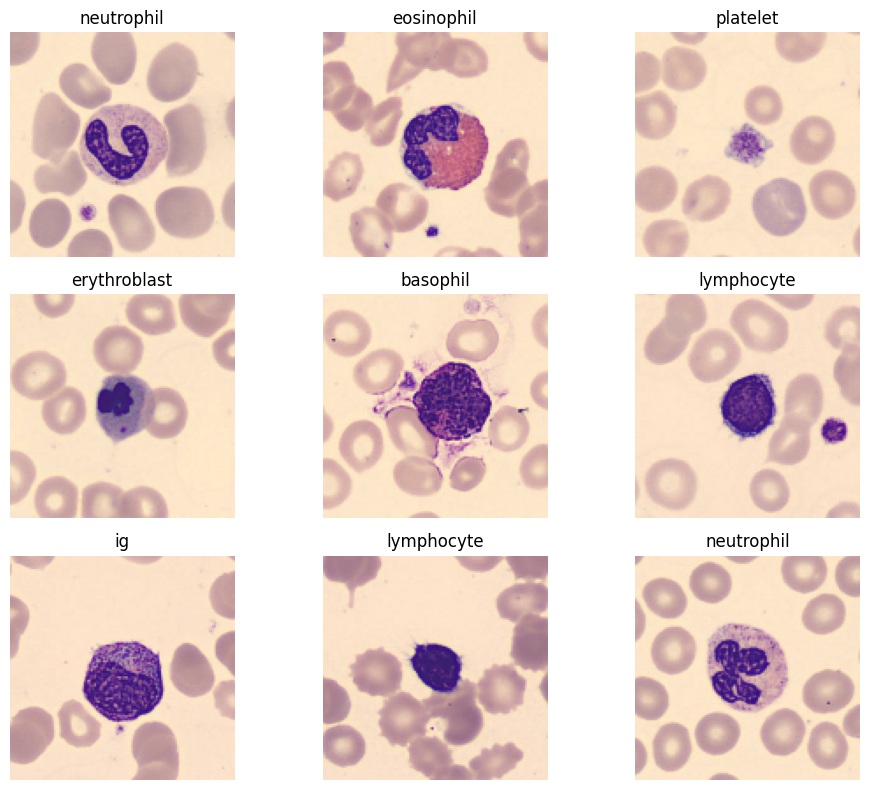

In [11]:
DATA_DIR = "/kaggle/input/datasets/unclesamulus/blood-cells-image-dataset/bloodcells_dataset"

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

print("Dataset path:", DATA_DIR)
print("Dataset exists:", os.path.exists(DATA_DIR))

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names

print("Blood cell classes:", class_names)
print("Number of classes:", len(class_names))

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)

print("Training and validation datasets are ready!")

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.tight_layout()
plt.show()

Step 3: Build the CNN model

In [12]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    # Normalize image pixels
    layers.Rescaling(1.0 / 255),

    # Convolution block 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convolution block 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),
    layers.Dense(len(class_names), activation="softmax")
])

model.summary()

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,672 (12.61 MB)

 Trainable params: 3,305,672 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

Model compiled successfully!


Step 4: Train the model

In [13]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stop]
)

Epoch 1/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 193s 447ms/step - accuracy: 0.5753 - loss: 1.1368 - val_accuracy: 0.7858 - val_loss: 0.5566
Epoch 2/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 207s 458ms/step - accuracy: 0.7648 - loss: 0.6387 - val_accuracy: 0.8487 - val_loss: 0.4109
Epoch 3/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 188s 439ms/step - accuracy: 0.8031 - loss: 0.5276 - val_accuracy: 0.8719 - val_loss: 0.3608
Epoch 4/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 190s 443ms/step - accuracy: 0.8426 - loss: 0.4316 - val_accuracy: 0.9011 - val_loss: 0.2830
Epoch 5/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 190s 444ms/step - accuracy: 0.8708 - loss: 0.3595 - val_accuracy: 0.9286 - val_loss: 0.2130
Epoch 6/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 188s 438ms/step - accuracy: 0.8860 - loss: 0.3154 - val_accuracy: 0.9055 - val_loss: 0.2422
Epoch 7/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 187s 438ms/step - accuracy: 0.9017 - loss: 0.2844 - val_accuracy: 0.9429 - val_loss: 0.1782
Epoch 8/15
428/428 ━━━━━━━━━━━━━━━━━━━━ 188s 438ms/step - accuracy: 0.9125 -

step 5: Accuracy amd loss graphs

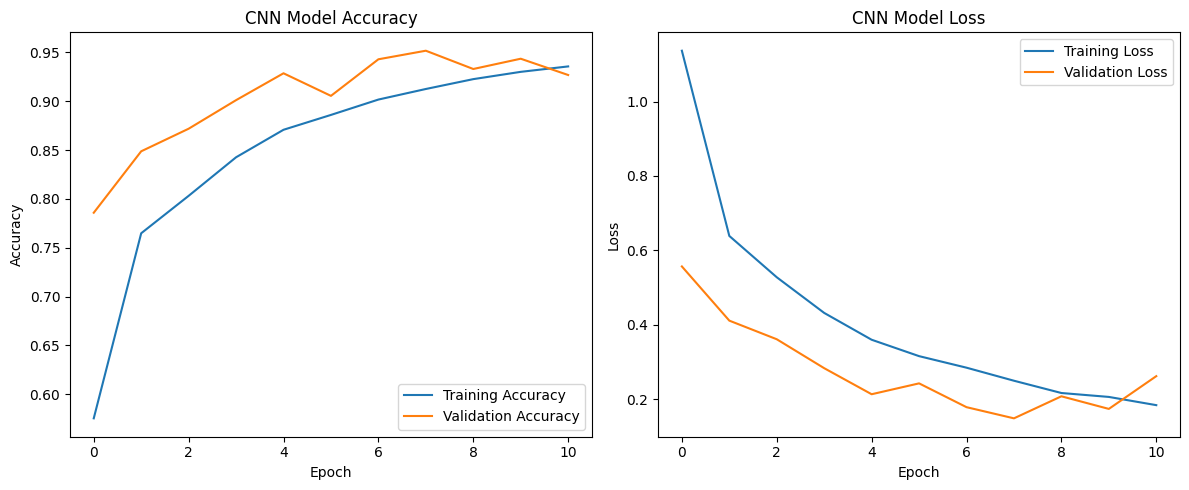

In [14]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

Step 6: Model evaluation

In [15]:
val_loss, val_accuracy = model.evaluate(val_ds)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

107/107 ━━━━━━━━━━━━━━━━━━━━ 12s 112ms/step - accuracy: 0.9517 - loss: 0.1481
Validation Loss: 0.1481
Validation Accuracy: 95.17%


Step 7: Classification report and confusion matrix

107/107 ━━━━━━━━━━━━━━━━━━━━ 12s 115ms/step
              precision    recall  f1-score   support

    basophil       0.05      0.05      0.05       237
  eosinophil       0.18      0.18      0.18       596
erythroblast       0.06      0.06      0.06       294
          ig       0.16      0.18      0.17       602
  lymphocyte       0.07      0.07      0.07       241
    monocyte       0.08      0.07      0.08       307
  neutrophil       0.20      0.20      0.20       679
    platelet       0.14      0.14      0.14       462

    accuracy                           0.14      3418
   macro avg       0.12      0.12      0.12      3418
weighted avg       0.14      0.14      0.14      3418



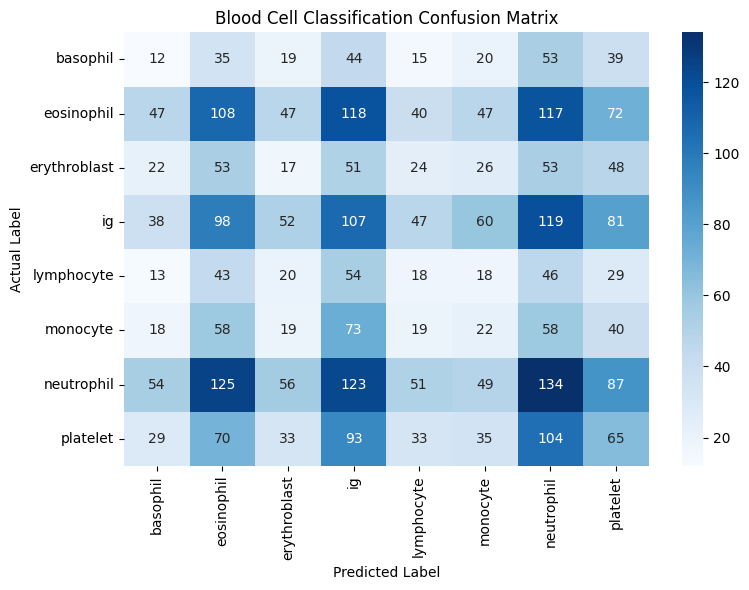

In [16]:
y_true = np.concatenate([
    labels.numpy()
    for _, labels in val_ds
])

y_prob = model.predict(val_ds)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Blood Cell Classification Confusion Matrix")
plt.tight_layout()
plt.show()

Step 8: Trained model save

In [17]:
model.save("/kaggle/working/blood_cell_cnn.keras")

print("Model saved successfully!")

Model saved successfully!
